In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [2]:
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
import matplotlib
from sklearn.manifold import TSNE
import torch
from Experiment_10.net import Net
import torch
from Experiment_10.ParametricWMTask import generate_trials
from sklearn.decomposition import PCA
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5
from torch.utils.data import TensorDataset, DataLoader

In [191]:



u, z, mask, conditions = generate_trials(n_trials=5)


import numpy as np
import statsmodels.api as sm
import pandas as pd
#
net = Net(n=100, input_size=u.shape[2],output_size=u.shape[2],
          dale=False,
          sigma_in=0.,
          sigma_rec = 0.,
          base_in=0.,
          lambda_std=0.4,
          beta=
          50)


# Fit 4
dim = 4
epochs =1000
my_dataset = TensorDataset(u, z, mask)  # create your datset
my_dataloader = DataLoader(my_dataset, batch_size=64, shuffle=True)

optimizer = torch.optim.Adam(net.parameters(), lr=.001, weight_decay=0.001)
epoch = 0
# mse_z=1
# lds = LDS(n=dim, hidden_n = 5).to(device)

while epoch < epochs:

    # Fit LDS model to full dataset after z-scoring
    #  x = self.forward(u)
    # x = (x - torch.mean(x, dim=[0, 1])) / (torch.std(x, dim=[0, 1]) + 1e-4)
    # lds.fit(u, x.detach())
    # lds_error_mean, lds_error_std = self.linear_error(lds.output_layer(lds(u)).detach(), x)

    # pca = PCA(n_components=dim).fit(x.reshape(-1, x.shape[2]).detach().numpy())
    #  pcs = torch.tensor(pca.components_[:dim, :]).float()

    for batch_idx, (u_batch, z_batch, mask_batch) in enumerate(my_dataloader):

        optimizer.zero_grad()

        # Z-score batch data
        x_batch = net.forward(u_batch, training=True)
        x_batch_centered = (x_batch - torch.mean(x_batch, dim=[0, 1])) / (torch.std(x_batch, dim=[0, 1]) + 1e-4)

        # K Means

        # PCA
        eigs = torch.sort(torch.real(
            torch.linalg.eigvals(torch.cov(x_batch_centered.reshape(-1, x_batch_centered.shape[2]).t()))),
                          descending=True)[0]
        pca_error = torch.sum(eigs[dim:]) / torch.sum(eigs)
        pca_1 = eigs[dim - 1] / torch.sum(eigs)


        # Z-score

        h = torch.abs(torch.diff(x_batch_centered,dim=1)/(x_batch_centered[:,:-1,:]+10))
        g = torch.mean(h,dim=(0,1))
        gain_loss = torch.mean(g)


        loss = 100*gain_loss +  1*(pca_1- 1/dim)**2 + 1*pca_error  +.4 * torch.std(torch.std(x_batch, dim=[0, 1])) + \
            .4* torch.std(torch.mean(x_batch, dim=[0, 1]))

        loss.backward()
        optimizer.step()
        net.recurrent_layer.bias.data = torch.nn.ReLU()(net.recurrent_layer.bias.data)

        epoch += 1

        if epoch % 10 == 0:
            print('Epoch: {}/{}.............'.format(epoch, epochs), end=' ')
            print("g: {:.4f}".format(gain_loss.item()), end=' ')
            print("pca: {:.4f}".format(pca_error.item()), end=' ')
            print("pca_1: {:.4f}".format(pca_1.item()))

                    # print("lds: {:.4f}".format(self.linear_error(linear_prediction,x_batch).item()))


Epoch: 10/1000............. g: 0.0041 pca: 0.0719 pca_1: 0.0653
Epoch: 20/1000............. g: 0.0039 pca: 0.0540 pca_1: 0.0622
Epoch: 30/1000............. g: 0.0036 pca: 0.0480 pca_1: 0.0697
Epoch: 40/1000............. g: 0.0030 pca: 0.0396 pca_1: 0.0981
Epoch: 50/1000............. g: 0.0029 pca: 0.0281 pca_1: 0.0959
Epoch: 60/1000............. g: 0.0028 pca: 0.0226 pca_1: 0.0987
Epoch: 70/1000............. g: 0.0028 pca: 0.0184 pca_1: 0.1014
Epoch: 80/1000............. g: 0.0028 pca: 0.0145 pca_1: 0.1045
Epoch: 90/1000............. g: 0.0027 pca: 0.0132 pca_1: 0.0921
Epoch: 100/1000............. g: 0.0026 pca: 0.0132 pca_1: 0.0841
Epoch: 110/1000............. g: 0.0024 pca: 0.0106 pca_1: 0.0745
Epoch: 120/1000............. g: 0.0024 pca: 0.0111 pca_1: 0.0562
Epoch: 130/1000............. g: 0.0023 pca: 0.0101 pca_1: 0.0666
Epoch: 140/1000............. g: 0.0023 pca: 0.0114 pca_1: 0.0539
Epoch: 150/1000............. g: 0.0023 pca: 0.0108 pca_1: 0.0691
Epoch: 160/1000............. g: 0.

In [192]:
##################################################################
############################## SNR  ##############################
##################################################################
u, z, mask, conditions = generate_trials(n_trials=25,n_t = 75)
net.sigma_rec =0
x = net(u).detach()

# x = iterative_outlier_detection(x)
# response_rows = []
# for trial in range(x.shape[0]):
#     response_rows.append({"trial": trial,
#                  'motion_coh': conditions[trial]['motion_coh'].item(),
#                  'y': x[trial, :, :],})
# response_df = pd.DataFrame(response_rows)
# new_df = response_df.groupby('motion_coh').y.apply(lambda x: np.stack(x)).reset_index()
# response_matrix = np.stack(new_df.y.values) # (n_conditions x trials_per_condition x time x n_neurons)
# response_matrix = (response_matrix - np.mean(response_matrix, axis=(0, 1, 2), keepdims=True)) / np.std(
# response_matrix, axis=(0, 1, 2), keepdims=True)
#
# # Mean responses across trials per condition
# responses = np.mean(response_matrix, axis=1) # (n_conditions x time x neurons)
# responses = responses.reshape(-1, responses.shape[2]) # (n_conditions.time x neurons)
x = (x - torch.mean(x, dim=[0, 1])) / (torch.std(x, dim=[0, 1]) + 1e-4)

h = torch.abs(torch.diff(x,dim=1)/(x[:,:-1,:]+10))
snr = torch.mean(h,dim=(0,1)).detach()

# Within condition deviation
#snr = np.mean(np.std(response_matrix, axis=1), axis=(0, 1))

In [193]:
responses.shape

NameError: name 'responses' is not defined

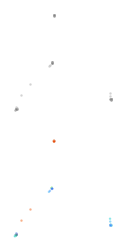

In [194]:
####################################################################
#################### CLUSTERING PLOT ###############################
####################################################################
import umap
net.sigma_rec = 0

x = net(u).detach()
# h = net.recurrent_layer(x) + net.input_layer(u)
# h = h - torch.mean(h, dim=(0, 1), keepdim=True)
#
# z = x - torch.mean(x, dim=[0, 1], keepdim=True)
# # dist = torch.var(z @ self.recurrent_layer.weight.t()) / torch.var(h, dim=(0, 1))
#
# beta = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))
#
# mag = torch.mean(x,dim = (0,1))

#x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
#x = x  + 2*(2*torch.rand_like(x)-1)
x = x.detach().numpy()
x_proj  = PCA(n_components = 2).fit_transform(x.reshape(-1,x.shape[2]).T)
#x_proj  = TSNE(n_components = 2,perplexity = 200).fit_transform(x.reshape(-1,x.shape[2]).T)
#x_proj  = TSNE(n_components = 2,perplexity = 200).fit_transform(responses.T)
# fit = umap.UMAP(densmap=True,dens_lambda =4)
# x_proj= fit.fit_transform(x.reshape(-1,x.shape[2]).T)
fig = plt.figure(figsize=(3,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=3,ax=ax0,color='gray',alpha = .35,legend = False)
#sns.kdeplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax0,color='gray',fill = True,legend = False,levels = 20,alpha = .5)

sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=3,hue =snr,alpha = .5,legend = False,palette = 'turbo')
for ax in [ax0,ax1]:
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_.jpg')


In [210]:
u, z, mask, conditions = generate_trials(n_trials=1,n_t= 400,n_conditions = 300)
net.alpha = .01
x = net(u)
#x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach().numpy()
pca = PCA().fit(x.reshape(-1,x.shape[2]))


In [211]:
net.sigma_rec

0

In [216]:
##########################################
########## Plotting manifolds ############
##########################################


rows = []
x = torch.tensor(x).float()
#net.recurrent_layer.weight.data = net.recurrent_layer.weight.data + .005*(2*torch.randn_like(net.recurrent_layer.weight.data)-1)
h = net.recurrent_layer(x)+net.input_layer(u)

flow_field = -x + net.activation(h)
e = torch.exp(1*h)
b = 1*e/((1+e)**2)

curvature =  (flow_field @ net.recurrent_layer.weight.data.t())**2 * b

for trial in range(x.shape[0]):
    trajectory = x[trial,:,:]
    proj_trajectory = pca.transform(trajectory)
    for t in range(x.shape[1]):

        rows.append({'t': t,
             'theta': conditions[trial]['theta'],
             'x': proj_trajectory[t,0],
             'y': proj_trajectory[t,1],
             'z': proj_trajectory[t,2],
             'c': torch.linalg.norm(curvature[trial,t,:]).item(),

              'b':torch.linalg.norm(b[trial,t,:]).item()})

new_df = pd.DataFrame(rows)

x.shape

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_85119/2651543379.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x = torch.tensor(x).float()


torch.Size([300, 400, 100])

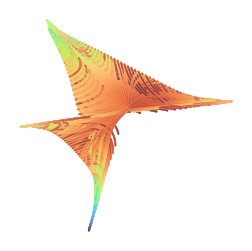

In [217]:
fig = plt.figure(figsize=(3,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)

ax0=fig.add_subplot(gs[0,0])


sns.scatterplot(data = new_df, x = 'z', y = 'y', hue = 'b',palette = 'turbo',s=2,legend=False,alpha = .25,ax=ax0)
# sns.scatterplot(data = new_df[new_df.t<int(200*.4)], x = 'y', y = 'z', c = new_df[new_df.t<int(200*.4)].c_2.values,cmap = 'turbo',s=1,legend=False,alpha = .25,ax=ax1,vmin = vmin,vmax = vmax)
# sns.scatterplot(data = new_df[new_df.t<int(200*.4)], x = 'y', y = 'z', c = new_df[new_df.t<int(200*.4)].b_3.values,cmap = 'turbo',s=1,legend=False,alpha = .25,ax=ax2,vmin = vmin,vmax = vmax)
# sns.scatterplot(data = new_df[new_df.t<int(200*.4)], x = 'y', y = 'z', c = new_df[new_df.t<int(200*.4)].b_6.values,cmap = 'turbo',s=1,legend=False,alpha = .25,ax=ax3,vmin = vmin,vmax = vmax)
# sns.scatterplot(data = new_df[new_df.t<int(200*.4)], x = 'y', y = 'z', c = new_df[new_df.t<int(200*.4)].b_min.values,cmap = 'turbo',s=1,legend=False,alpha = .25,ax=ax4,vmin = vmin,vmax = vmax)

# sns.scatterplot(data = new_df[new_df.t<int(200*.4)], x = 'z', y = 'x', hue = 'b_1',palette = 'turbo',s=1,legend=False,alpha = .25,ax=ax1)
# sns.scatterplot(data = new_df[new_df.t<int(200*.4)], x = 'y', y = 'z', hue = 'c',palette = 'turbo',s=1,legend=False,alpha = .15,ax=ax2,hue_norm = (0,.01))


#sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax3,s=4,color='gray',alpha = 1)

for ax in [ax0]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    plt.savefig('Figures/Figure_boundary_8.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)
# ax.spines['left'].set_color('black')
# ax.spines['bottom'].set_color('black')


In [163]:

# Convert population response to 2d array
from scipy.ndimage import gaussian_filter
embedding =(60*x_proj[:,:2]).astype(int) - (60*x_proj[:,:2]).astype(int).min()
def spatial_embedding(response,embedding,sigma):
    m = np.zeros((embedding.max()+1,embedding.max()+1))
    for neuron in range(embedding.shape[0]):
        m[embedding[neuron,1],embedding[neuron,0]] = response[neuron]
    m = np.flipud(m)
    return gaussian_filter(m,sigma)


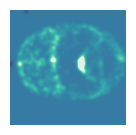

In [26]:
t = 40
trial = 0
vmin = -.035
vmax = .035
sigma = 6
response = x[trial,t,:]
m = spatial_embedding(response,embedding,sigma)
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.heatmap(m ,vmin = vmin,vmax = vmax,cbar = False,ax=ax,cmap = 'mako', center=0)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_'+str(t)+'.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

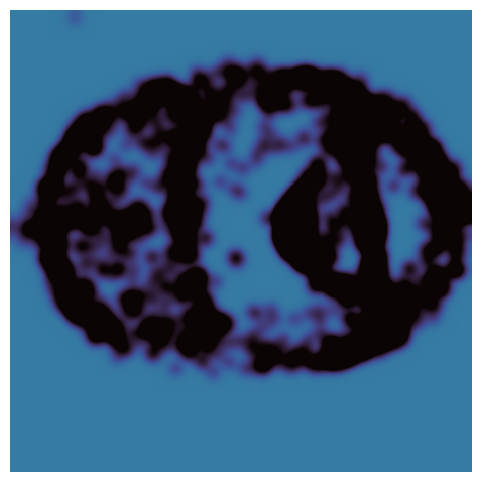

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation


num_frames = 75
trial = 0
data_list = [spatial_embedding(x[trial,i,:],embedding,sigma) for i in range(num_frames)]

# 2. Set up the figure and axes
fig, ax = plt.subplots(figsize=(6, 6))

def update(frame_num):
    """Updates the heatmap for each frame of the animation."""
    ax.clear()  # Clear the previous frame's axis
    current_data = data_list[frame_num]
    sns.heatmap(current_data, ax=ax, cbar=False, vmin=vmin, vmax=vmax, center=0,cmap = 'mako')

    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
# 3. Create the animation object
# interval is the delay between frames in milliseconds
anim = FuncAnimation(fig, update, frames=num_frames, interval=200, blit=False)

# 4. Save the animation as a movie file
# You need a writer installed (e.g., 'ffmpeg' or 'pillow')
# Ensure you have the necessary writer installed (e.g., 'conda install -c conda-forge ffmpeg')
anim.save('Movies/model_1/trial_1.mp4', writer='ffmpeg', fps=5)

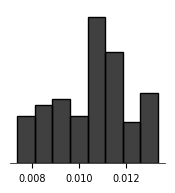

In [83]:


fig = plt.figure(figsize=(2, 2))
from scipy.spatial import ConvexHull

gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])
sns.histplot(x = snr,ax=ax,color='black',stat = 'probability')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel('')
#ax.set_xlim(.2,1)

ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)


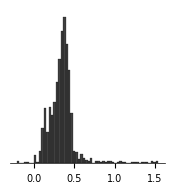

In [91]:


fig = plt.figure(figsize=(2, 2))
from scipy.spatial import ConvexHull

gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])
sns.histplot(x = beta.detach(),ax=ax,color='black',stat = 'probability')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel('')
#ax.set_xlim(.2,1)

ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)


In [35]:
torch.save(beta.detach(), '../../BWM/ScriptsandFunctions/target_beta.pth')
torch.save(snr, '../../BWM/ScriptsandFunctions/target_snr.pth')

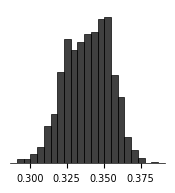

In [32]:
fig = plt.figure(figsize=(2, 2))
from scipy.spatial import ConvexHull
x = net(u).detach().numpy()
gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])
sns.histplot(x = np.mean(x,axis = (0,1)),ax=ax,color='black',stat = 'probability')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel('')
#ax.set_xlim(.2,1)

ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)


<Axes: xlabel='None'>

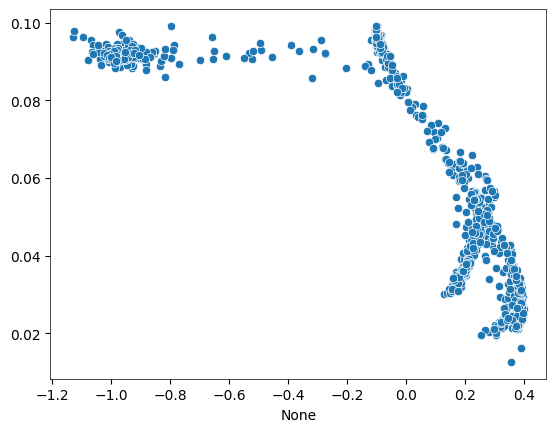

In [184]:
plt.figure()
sns.scatterplot(x = beta.detach(),y = snr)

(-0.08750071302056313, 0.13916621282696723)

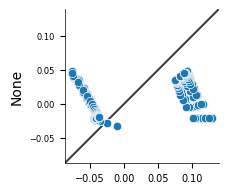

In [186]:
fig = plt.figure(figsize=(2, 2))

gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])
sns.scatterplot(x = h[:,:,0].detach().flatten(),y = z[:,:,0].detach().flatten(),ax=ax)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.set_xlabel('')
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
lims = [
    np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
    np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
]

# now plot both limits against eachother
ax.plot(lims, lims, 'k-', alpha=0.75, zorder=0)
ax.set_aspect('equal')
ax.set_xlim(lims)
ax.set_ylim(lims)


<Axes: ylabel='Count'>

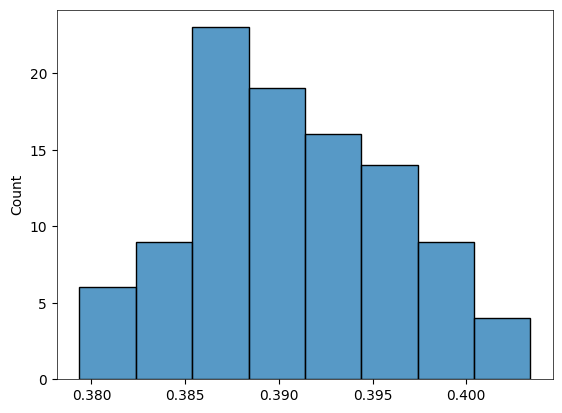

In [118]:
plt.figure()
x  = net(u).detach().numpy()
sns.histplot(np.mean(x,axis=(0,1)))

<Axes: ylabel='Count'>

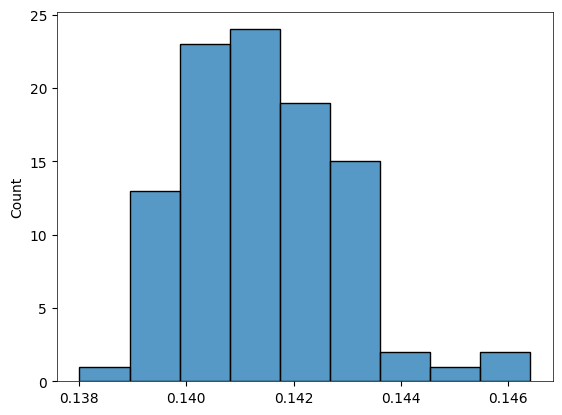

In [119]:
plt.figure()
x  = net(u).detach().numpy()
sns.histplot(np.std(x,axis=(0,1)))

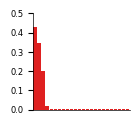

In [120]:
# Dimensionality
x = net(u)
x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach().numpy()

pca = PCA().fit(x.reshape(-1,x.shape[2]))



fig = plt.figure(figsize=(1.25, 1.25))
from scipy.spatial import ConvexHull

gs = gridspec.GridSpec(1, 1)

ax = fig.add_subplot(gs[0, 0])

sns.barplot(x = np.arange(1,25),y = pca.explained_variance_ratio_[:24],color='red')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)

ax.set_ylim(0,.5)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)


In [11]:
np.mean((pca.explained_variance_ratio_[:25] - dimensionality[:25])**2)

np.float64(0.0018729447632394218)

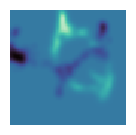

In [74]:
#########################################################################
######################## CONNECTIVITY KERNEL ############################
#########################################################################

# Color neurons and their corresponding location by a row of the connectivity matrix.
w_rec = net.recurrent_layer.weight.detach().numpy()
fixed_neuron = 80
embedding =(10*x_proj[:,:2]).astype(int) - (10*x_proj[:,:2]).astype(int).min()
def spatial_embedding(response,embedding,sigma):
    m = np.zeros((embedding.max()+1,embedding.max()+1))
    for neuron in range(embedding.shape[0]):
        m[embedding[neuron,1],embedding[neuron,0]] = w_rec[fixed_neuron,neuron]
    m = np.flipud(m)
    return gaussian_filter(m,sigma)

t = 40
trial = 0
vmin = -.01
vmax = .01
sigma = 2
response = x[trial,t,:]
m = spatial_embedding(response,embedding,sigma)
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.heatmap(m ,cbar = False,ax=ax,cmap = 'mako', center=0)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_'+str(t)+'.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [ ]:
m

<Axes: >

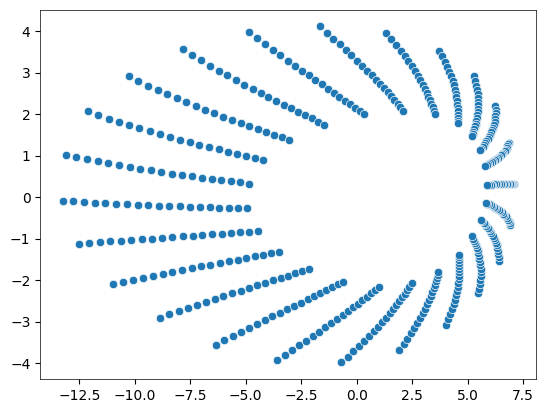

In [9]:
##########################################
########## Plotting manifolds ############
##########################################
#u, z, mask, conditions = generate_trials(n_trials=1,n_t = 200,n_conditions =400)
#net.alpha = .05
x = net(u)
x  = x[:,56:,:]
#x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach().numpy()
x_proj  = PCA().fit_transform(x.reshape(-1,x.shape[2]))
plt.figure()
sns.scatterplot(x = x_proj[:,0] ,y = x_proj[:,1])


In [61]:
#####################################################
################# Signal to noise ###################
#####################################################
u, z, mask, conditions = generate_trials(n_trials=25,n_t = 75,n_conditions =50)
net.sigma_rec =1
x = net(u)


# Condition averages
x = x.detach().cpu().numpy()
# x = iterative_outlier_detection(x)
rows = []
for trial in range(x.shape[0]):
    rows.append({"trial": trial,
                 'theta': conditions[trial]['theta'].item(),
                 'y': x[trial, :, :],})
response_df = pd.DataFrame(rows)
new_df = response_df.groupby('theta').y.apply(lambda x: np.stack(x)).reset_index()
response_matrix = np.stack(new_df.y.values) # (n_conditions x trials_per_condition x time x n_neurons)
print(response_matrix.shape)
response_matrix = (response_matrix - np.mean(response_matrix, axis=(0, 1, 2), keepdims=True)) / np.std(
response_matrix, axis=(0, 1, 2), keepdims=True)

# Mean responses across trials per condition
responses = np.mean(response_matrix, axis=1) # (n_conditions x time x neurons)
responses = responses.reshape(-1, responses.shape[2]) # (n_conditions.time x neurons)

print(responses.shape)


# PCA error
pca = PCA().fit(responses)
pca_error = np.sum(pca.explained_variance_ratio_[dim:])

# K Means error

# Within condition deviation
snr = np.mean(np.std(response_matrix, axis=1), axis=(0, 1))
snr_mean = np.mean(snr)

# Compute gain
x = torch.tensor(x).float()
h = net.recurrent_layer(x) + net.input_layer(u)
h = h - torch.mean(h, dim=(0, 1), keepdim=True)

z = x - torch.mean(x, dim=[0, 1], keepdim=True)
gain = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))
gain_mean = torch.mean(gain).item()
gain_std = torch.std(gain).item()

(50, 25, 75, 1000)
(3750, 1000)


In [57]:
snr.shape

(1000,)

In [58]:
gain.shape

torch.Size([1000])

<Axes: ylabel='None'>

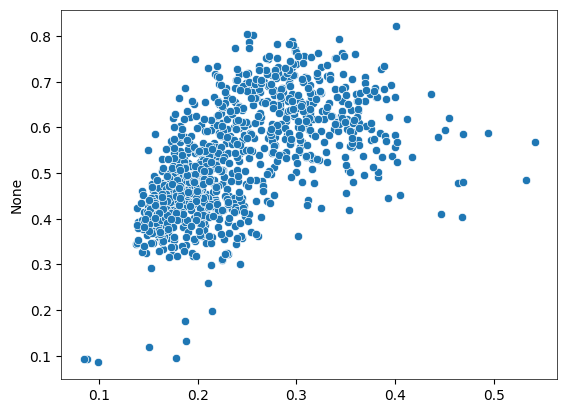

In [62]:
plt.figure()
sns.scatterplot(x = snr,y  = gain.detach())

In [64]:

u, z, mask, conditions = generate_trials(n_trials=25,n_t = 75,n_conditions =50)

x = net(u)


# Condition averages
x = x.detach().cpu().numpy()
# x = iterative_outlier_detection(x)
response_rows = []
for trial in range(x.shape[0]):
    response_rows.append({"trial": trial,
                 'theta': conditions[trial]['theta'].item(),
                 'y': x[trial, :, :],})
response_df = pd.DataFrame(response_rows)
new_df = response_df.groupby('theta').y.apply(lambda x: np.stack(x)).reset_index()
response_matrix = np.stack(new_df.y.values) # (n_conditions x trials_per_condition x time x n_neurons)
response_matrix = (response_matrix - np.mean(response_matrix, axis=(0, 1, 2), keepdims=True)) / np.std(
response_matrix, axis=(0, 1, 2), keepdims=True)

# Mean responses across trials per condition
responses = np.mean(response_matrix, axis=1) # (n_conditions x time x neurons)
responses = responses.reshape(-1, responses.shape[2]) # (n_conditions.time x neurons)





# Within condition deviation
snr = np.mean(np.std(response_matrix, axis=1), axis=(0, 1))
snr_mean = np.mean(snr)

# Compute gain
x = torch.tensor(x).float()
h = net.recurrent_layer(x) + net.input_layer(u)
h = h - torch.mean(h, dim=(0, 1), keepdim=True)

z = x - torch.mean(x, dim=[0, 1], keepdim=True)
gain = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))




<Axes: xlabel='None'>

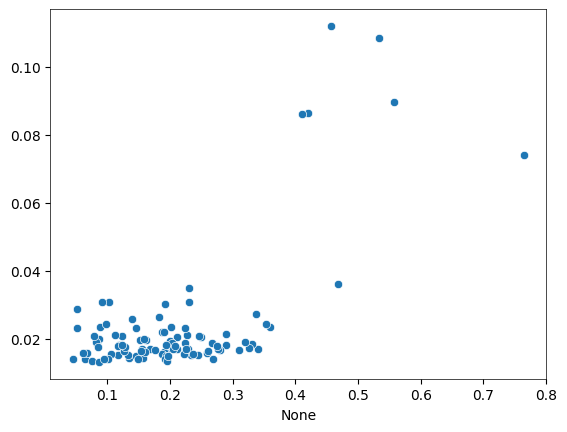

In [66]:
plt.figure()
sns.scatterplot(y = snr,x  = gain.detach())